# 02 · 若依项目实战篇（AI+若依）


## 本章来源与学习路线

本篇对应百度网盘 **`我的资源/PPT(1)/03-项目实战篇.pptx`**，共 173 页，课件主项目是“帝可得”智能售货机运营管理系统。整理日期：2026-10-09。

课件把一个物联网售货机系统拆成 11 个连续主题：项目介绍、初始 AI、项目搭建、点位管理、人员管理、设备管理、策略管理、商品管理、工单管理、运营管理 App、设备屏幕端与订单管理。笔记保留课件的业务流程和实现顺序；SQL、Java、MyBatis 片段中标注为“整理示例”的内容，是为了把截图中的设计还原成可读的工程骨架。

学习顺序建议：先理解领域模型和角色，再掌握“代码生成器生成基础 CRUD → VO/关联查询完成业务改造 → 前端原型对齐 → 接口联调”的重复套路，最后看 App、屏幕端和支付链路如何复用后台能力。


## 1. 帝可得项目：把物联网设备变成可运营的业务系统

**为什么**：售货机本体只负责出货，真正的运营还需要区域、点位、合作商、员工、设备、货道、商品、折扣和工单等后台数据。系统要把“人、机、货、场”关联起来，并让消费者端、运营端、运维端和管理后台共享同一套业务事实。

**是什么**：物联网（IoT）是让物体通过网络连接并交换信息；智能售货机是 IoT 的典型应用。帝可得在此基础上提供设备自管理、人员与设备绑定、移动支付、智能分析/推荐和线上线下融合（OMO）。

| 角色 | 主要职责 |
|---|---|
| 管理员 | 管理区域、点位、设备、货道、商品、策略；创建工单、查看订单和报表 |
| 运维人员 | 投放、撤除、维修设备 |
| 运营人员 | 给货道补货 |
| 合作商 | 提供点位并参与分成 |
| 消费者 | 在设备屏幕或小程序下单购买 |

业务术语要先统一：**区域**是运营范围的逻辑分区；**点位**是设备的实际放置位置；**货道**是售货机内部承载商品的槽位。


## 项目原型与设备示意

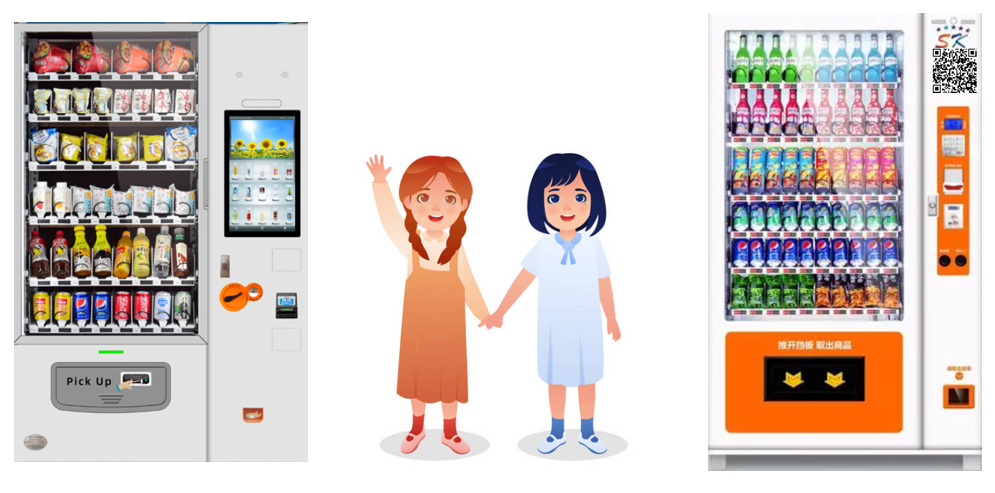

产品原型用于确认页面字段、按钮和流程，课件给出的原型地址是 [腾讯 CoDesign](https://codesign.qq.com/s/426304924036117)。开发时先以原型和需求为准，再用若依代码生成器产出可运行的基础页面。


## 2. 领域模型与数据建模方法

**为什么**：项目的功能不是一张表的 CRUD。点位要关联区域和合作商，设备要关联点位与设备类型，货道要关联设备和商品，工单还要关联员工、设备和工单明细。先画关系，再生成代码，能避免把业务规则硬塞进控制器。

**核心关系**：

```text
区域 1 ── N 点位 N ── 1 合作商
点位 1 ── N 售货机 N ── 1 设备类型
售货机 1 ── N 货道 N ── 0..1 商品
售货机 N ── 1 策略
员工 N ── 1 角色；员工 N ── 1 区域
工单 ── 售货机、员工、区域；补货工单 1 ── N 工单明细
```

课件截图中的表关系分别覆盖 `tb_region`、`tb_node`、`tb_partner`、`tb_vending_machine`、`tb_vm_type`、`tb_channel`、`tb_product`、`tb_policy`、`tb_emp`、`tb_task` 和相关类型/明细表。公共审计字段可复用若依 `BaseEntity`：创建人、创建时间、更新人、更新时间、备注和扩展参数。

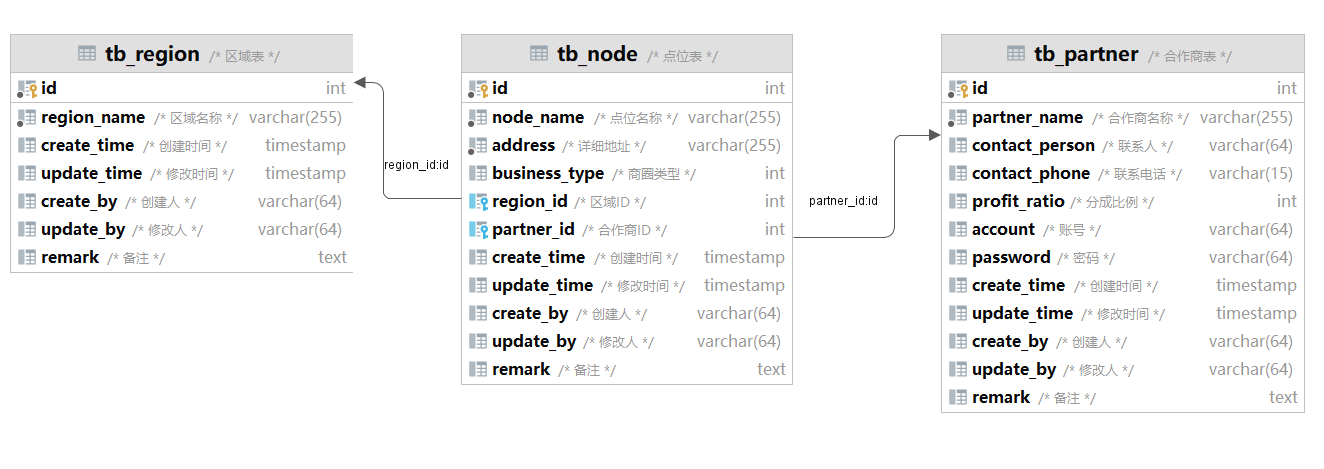

**整理示例**：外键字段（如 `region_id`、`partner_id`、`vm_id`）表达真实关系；冗余字段（如设备的地址、商圈类型、区域 ID）用于列表快速展示。冗余字段必须规定同步时机，否则查询快却容易出现旧数据。


## 3. 初始 AI：AIGC 与提示工程

**是什么**：AI（Artificial Intelligence）是用计算机模拟人类感知、学习、推理和决策的技术；AIGC（AI Generated Content）是用 AI 自动生成文本、代码、图片、音频和视频的应用分支；大模型是经过海量数据训练、具备通用生成与推理能力的机器学习模型。

| 概念 | 关注点 | 课件例子 |
|---|---|---|
| AI | 能否感知、学习、推理和决策 | 机器学习、深度学习 |
| AIGC | 能否自动生成内容 | 文本、代码、图片、音视频 |
| 通用大模型/AGI 产品 | 能否通过自然语言完成多类任务 | 文心一言、讯飞星火、通义千问、KIMI |

提示（Prompt）就是给模型的问题或指令；提示工程（Prompt Engineering）是设计和优化输入上下文，使输出更符合预期。把 AI 当成一位需要明确任务、背景和验收标准的协作者，效果通常比只说“帮我写代码”稳定。


## 4. Prompt 的六个组成部分

课件把一个可复用的 Prompt 拆成六块：

| 部分 | 作用 | 示例 |
|---|---|---|
| 角色 | 让模型采用匹配任务的视角 | 你是一位资深 Java 后端工程师 |
| 指示 | 明确要完成的动作 | 根据表结构设计 REST CRUD |
| 上下文 | 提供项目、约束、背景 | 项目使用 Spring Boot、MyBatis、Java 11 |
| 例子 | 展示期望风格或边界 | 给出一个已有接口作为样例 |
| 输入 | 标出待处理的原始数据 | 粘贴 SQL、接口定义或报错日志 |
| 输出 | 规定格式，便于人读或程序解析 | 输出 Java 代码、JSON 或 Mermaid |

**整理示例模板**：

```text
角色：你是熟悉若依的 Java 11 工程师。
任务：为 tb_node 增加“区域下点位数量”的列表展示。
上下文：Spring Boot + MyBatis，列表接口返回 RegionVo。
输入：建表 SQL、现有 RegionMapper、前端字段。
约束：不改表结构；关联查询保持分页；给出文件路径和关键代码。
输出：先说明方案，再给出 XML、Java、前端改动和验证步骤。
```

编程场景的高频指令包括：让 AI 生成 MySQL 表结构、根据 SQL 写数据字典、把代码执行过程画成流程图。输出约束越具体，二义性越少。


## 5. 项目搭建：后端、前端与基础设施

**课件方案**：后端仓库为 [`dkd-parent`](https://gitee.com/yudian1991/dkd-parent.git)，前端仓库为 [`dkd-vue`](https://gitee.com/yudian1991/dkd-vue.git)。后端流程是克隆并初始化、导入 MySQL、配置数据库、启动 Redis、运行服务；前端流程是克隆、安装依赖、运行开发服务器。

**怎么用**：

1. 后端先确认父工程和各业务模块能被 Maven 识别，再导入数据库脚本。
2. 在配置文件中填写 MySQL 连接和 Redis 地址/密码；凭证放在本地配置或环境变量，不提交到仓库。
3. 前端安装依赖后启动 Vite 开发服务器，确认浏览器能打开登录页。
4. 用一个最小闭环验证环境：登录 → 查询一个列表 → 查看浏览器 Network 中的请求和响应。

常见问题是初始化慢、依赖下载慢、Redis 有密码却仍按无密码连接。课件强调使用国内 npm 镜像；命令中的参数应写为 `--registry=https://registry.npmmirror.com`。


## 6. 点位管理：从需求到基础 CRUD

**业务流程**：后台登录 → 新增区域 → 新增合作商 → 新增点位。点位管理的三个基础对象是区域、合作商和点位。

**整理示例字段**：

```sql
-- 示例，实际字段以课件/项目脚本为准
region(id, region_name, remark, create_time, update_time)
partner(id, partner_name, contact_person, mobile, ratio, account, password, ...)
node(id, node_name, address, business_type, region_id, partner_id, ...)
```

点位表使用 `region_id`、`partner_id` 表达归属，`business_type` 使用数据字典维护商圈类型。先在数据库中准备表，再在若依代码生成器中创建目录菜单、添加字典、配置生成信息、下载代码并导入前后端工程。生成器解决通用的增删改查，业务差异放在后续改造。


## 7. 区域管理改造：VO 与关联查询

需求要求区域列表显示每个区域的点位数，详情页显示当前区域下的点位列表。课件比较了两种方案：

| 方案 | 优点 | 风险 | 本项目选择 |
|---|---|---|---|
| 区域表保存点位数 | 列表快 | 点位新增、删除、迁移时必须同步维护 | 点位少时不优先 |
| 关联查询 `COUNT` | 数据单一来源，规则集中 | 查询需要 JOIN/GROUP BY | 课件采用 |

改造步骤：

1. 在 `RegionVo` 增加 `nodeCount` 和需要展示的派生字段。
2. `RegionMapper` / XML 增加返回 VO 的查询，使用 `LEFT JOIN` 保留没有点位的区域。
3. 在 Service 接口和实现类增加查询 VO 方法。
4. Controller 调整列表方法，前端表格绑定新字段。

```sql
SELECT r.id, r.region_name, COUNT(n.id) AS node_count
FROM tb_region r
LEFT JOIN tb_node n ON n.region_id = r.id
GROUP BY r.id, r.region_name;
```

**面试提示**：`LEFT JOIN` 与 `INNER JOIN` 的区别不只是语法；前者能保留“子表没有记录”的主表行，适合区域数量为 0 的列表。


## 8. 合作商管理改造：详情、统计与密码重置

合作商列表要显示点位数量，详情要展示合作商名称、联系人、联系电话和分成比例；重置密码时把初始密码设为 `123456`，但数据库中必须保存加密后的值。

前后端分离的实现顺序：

```text
原型/需求 → 接口文档 → Controller 接收 partnerId
          → 构造对象（id + 编码后的初始密码）
          → Service 更新 → Mapper 持久化
          → partner.js 抽取 API → Vue 弹窗/提示刷新
```

点位数量仍采用合作商与点位的关联查询。密码重置属于安全敏感操作，应记录操作日志，并让用户首次登录后修改密码；“123456”只表示课件演示的初始口令，不能作为生产默认策略。


## 9. 点位详情：嵌套查询与数据完整性

点位列表要同时显示区域、合作商等信息；点位详情要显示当前点位下的设备列表。课件采用两类 MyBatis 能力：

- 设备数量使用关联查询，在 Mapper 层封装统计 SQL。
- 区域、合作商对象使用 `resultMap` 的 `<association>` 嵌套查询；子集合可用 `<collection>`。

```xml
<resultMap id="NodeVoMap" type="com.example.node.domain.vo.NodeVo">
  <association property="region" column="region_id"
               select="selectRegionById"/>
  <association property="partner" column="partner_id"
               select="selectPartnerById"/>
  <collection property="machines" column="id"
              select="selectMachinesByNodeId"/>
</resultMap>
```

删除区域或合作商时，若仍有点位引用，应限制删除并返回友好提示。数据库约束负责兜底，Spring 的 `DataIntegrityViolationException`（底层常见 `SQLIntegrityConstraintViolationException`）由全局异常处理器统一转换为前端可读的错误响应。


## 10. 人员管理：角色、区域与冗余字段

**业务流程**：新增员工 → 关联角色 → 关联区域。人员数据模型通过 `role_id`、`region_id` 关联角色和区域，`status` 字典约定 `1=启用、0=停用`。课件还保留 `region_name`、`role_code`、`role_name` 等冗余字段，方便员工列表直接展示。

冗余字段的同步规则必须写清楚：区域名称修改时同步更新员工表；员工换区域时同时更新外键和展示字段；批量修复脚本要能重新从主表回填冗余值。否则列表虽快，最终会出现“员工属于 A 区域却显示 B 区域”的问题。

代码生成流程仍是创建菜单、字典、生成配置、导入代码，再把列表页改成原型要求的布局和筛选项。


## 11. 文件存储：从本地目录迁移到对象存储

若依默认把图片写入服务器本地目录。单机开发简单，但在多实例部署时会出现磁盘满、单点故障和实例之间文件不一致。可选方案包括 FastDFS、MinIO 和云对象存储。

阿里云 OSS（Object Storage Service）把文件作为对象存入 Bucket，通过网络访问，适合图片、音频和视频。课件给出的准备步骤是：实名认证 → 充值/开通 OSS → 创建 Bucket → 获取 AccessKey → 参照官方 SDK 编写示例 → 集成项目。

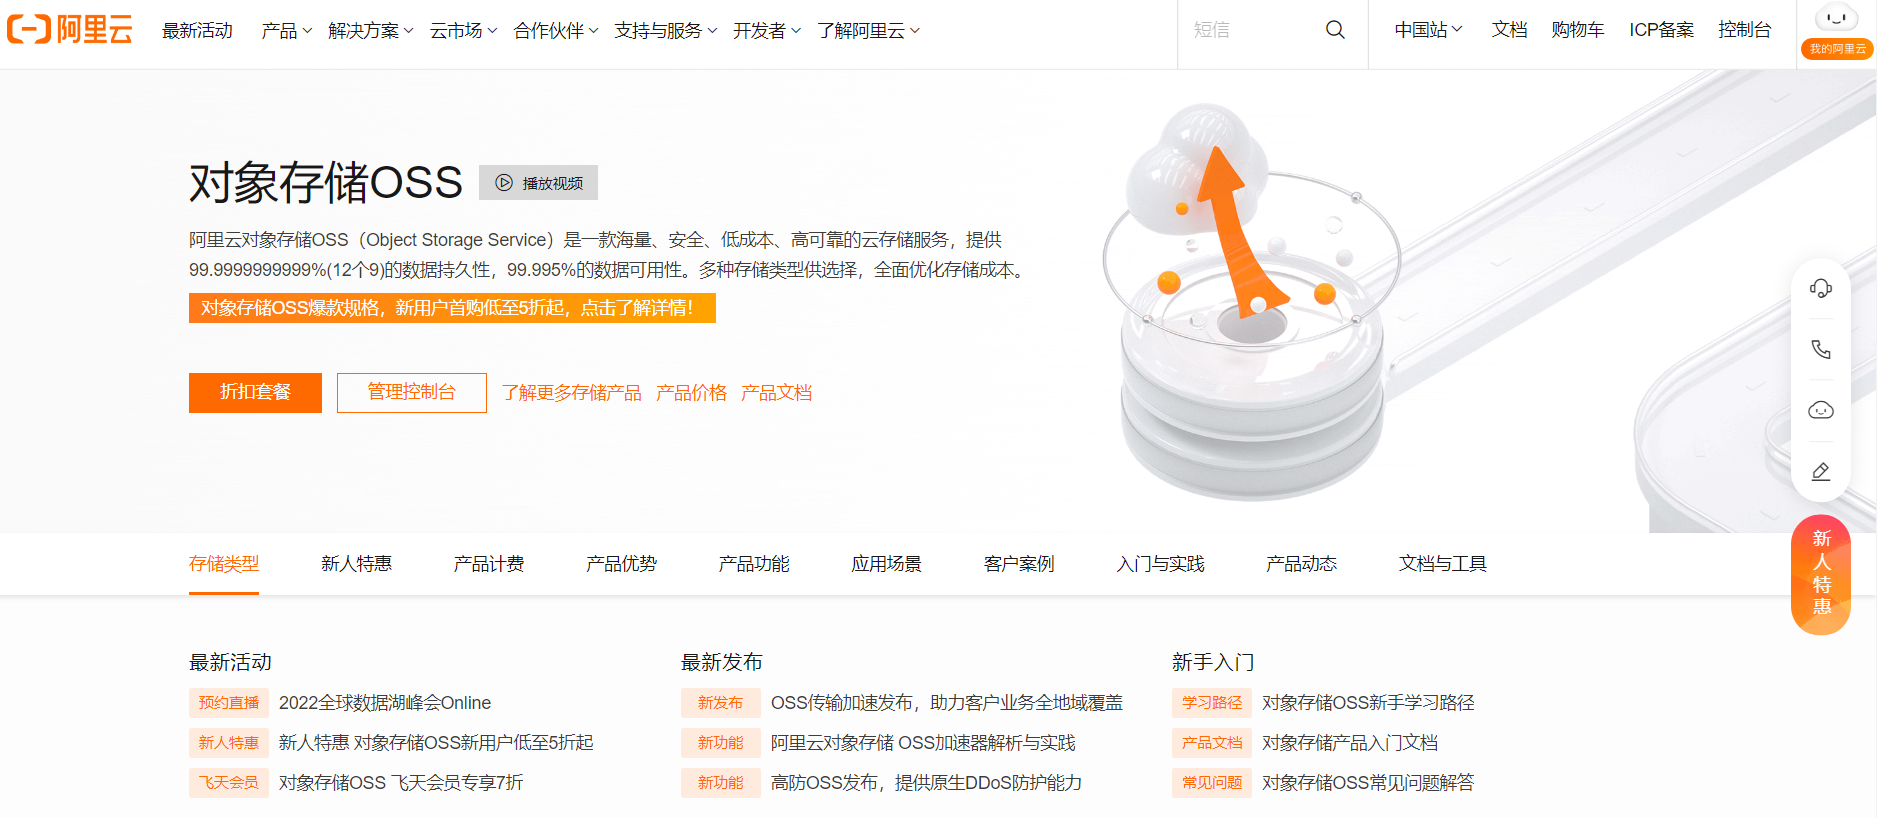

| 概念 | 含义 |
|---|---|
| SDK | 软件开发工具包，包含依赖、示例代码和调用封装 |
| Bucket | 存储对象的容器；每个文件对象必须属于某个 Bucket |
| AccessKey | 访问云服务的凭证，应放在环境变量/密钥管理中 |

课件还介绍 X File Storage，通过统一配置把文件写入本地、OSS、OBS、Kodo、COS 或其他 S3 兼容平台，减少业务代码与具体云厂商耦合。


## 12. 设备管理：设备类型、货道与状态

**业务流程**：新增设备类型 → 新增设备 → 新增货道 → 回到点位管理查看设备。设备状态字典为 `0=未投放、1=运营、3=撤机`；设备模型还会保存地址、商圈类型、区域 ID、合作商 ID 等派生信息。

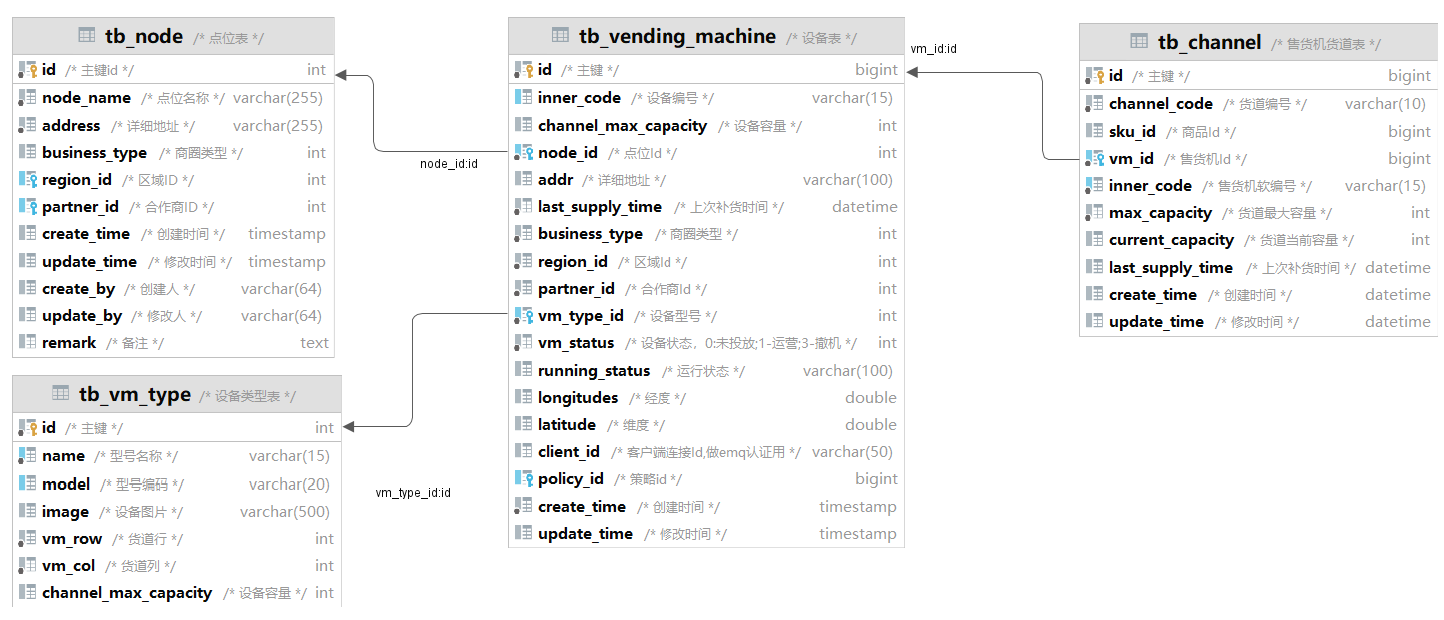

设备新增不能只插入一行设备记录：售货机类型决定货道数量和货道容量，因此要在一个事务中完成设备、货道和冗余字段的初始化。设备修改时，如果点位发生变化，应重新同步地址、商圈、区域和合作商信息。设备状态页需要单独配置前端路由和若依菜单权限。


## 13. 策略管理：固定折扣与设备分配

策略管理的业务流程是新增策略 → 在设备管理页给设备分配策略。策略表包含策略名称、折扣等信息，设备通过 `policy_id` 关联策略。

基础代码生成后，策略列表需要按原型调整；策略详情页展示策略名称和设备列表；设备页点击“策略”后设置固定折扣。分配动作应校验策略是否存在、设备是否存在，并在保存后刷新设备当前策略，避免前端显示旧值。

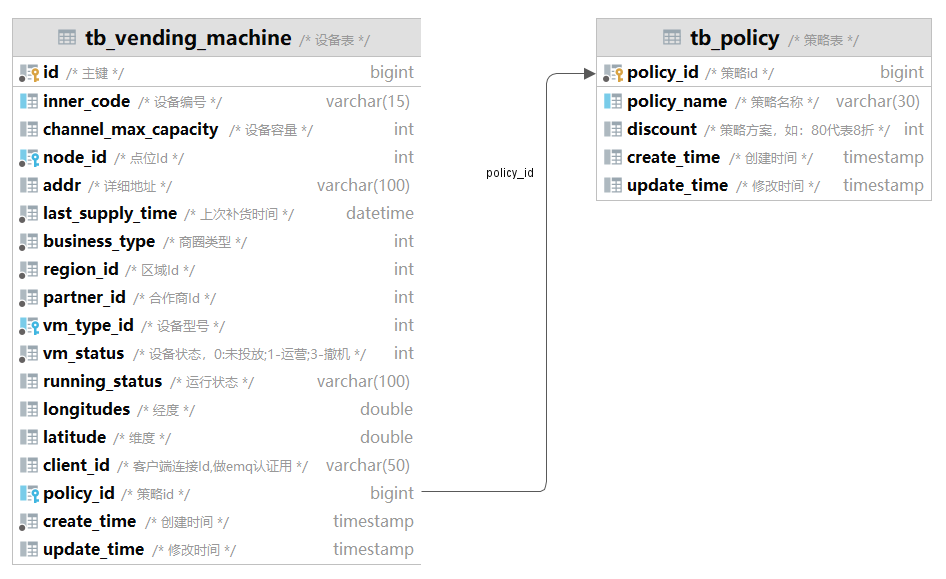


## 14. 商品管理：商品类型、商品与货道

商品管理包含商品类型、具体商品和货道关联三个模块。数据关系可概括为：商品属于商品类型（`class_id`），货道属于设备（`vm_id`），货道可关联商品（`sku_id`）。

删除商品时必须判断是否已有货道引用：

| 约束方式 | 做法 | 适用场景 |
|---|---|---|
| 物理外键约束 | 数据库阻止被引用记录删除 | 强一致、关系稳定 |
| 逻辑外键约束 | 删除前由 Service 查询引用并返回业务错误 | 需要自定义提示或跨库时 |

项目可用数据库约束兜底，再在 Service 提前检查，给出“商品已被货道关联，不能删除”的可读提示。


## 15. EasyExcel 批量导入

商品数量较大时，逐条录入会让运营效率很低。课件使用阿里开源的 EasyExcel 增强若依的 Excel 导入/导出能力，特点是 API 简单、功能完整、内存占用低。

批量导入的可靠流程：

1. 下载并校验模板，表头与字段类型固定。
2. 读取文件时做必填、枚举、长度和重复校验。
3. 在事务中批量写入；失败时返回行号和原因，避免只提示“导入失败”。
4. 导入成功后刷新商品列表，并记录操作日志。

```java
// 整理示例：监听器负责逐行校验，Service 负责事务批量落库
@Transactional
public ImportResult importProducts(MultipartFile file) {
    List<ProductRow> rows = excelReader.read(file);
    validator.validate(rows);
    productMapper.batchInsert(rows);
    return ImportResult.success(rows.size());
}
```


## 16. 货道关联商品：嵌套映射与批量配置

货道配置页先选择设备，再展示货道和商品。课件将工作拆成：查询设备类型（已完成）、按售货机编号查询货道列表、查询商品列表、完成货道关联。

查询货道时，Controller 接收 `innerCode`，Service 调用 Mapper；Mapper 在 XML 中手动映射 `ChannelVo`，并嵌套查询已关联的商品。保存时接收 `ChannelConfigDto`，转成持久化对象后按“售货机编号 + 货道编号”批量更新。

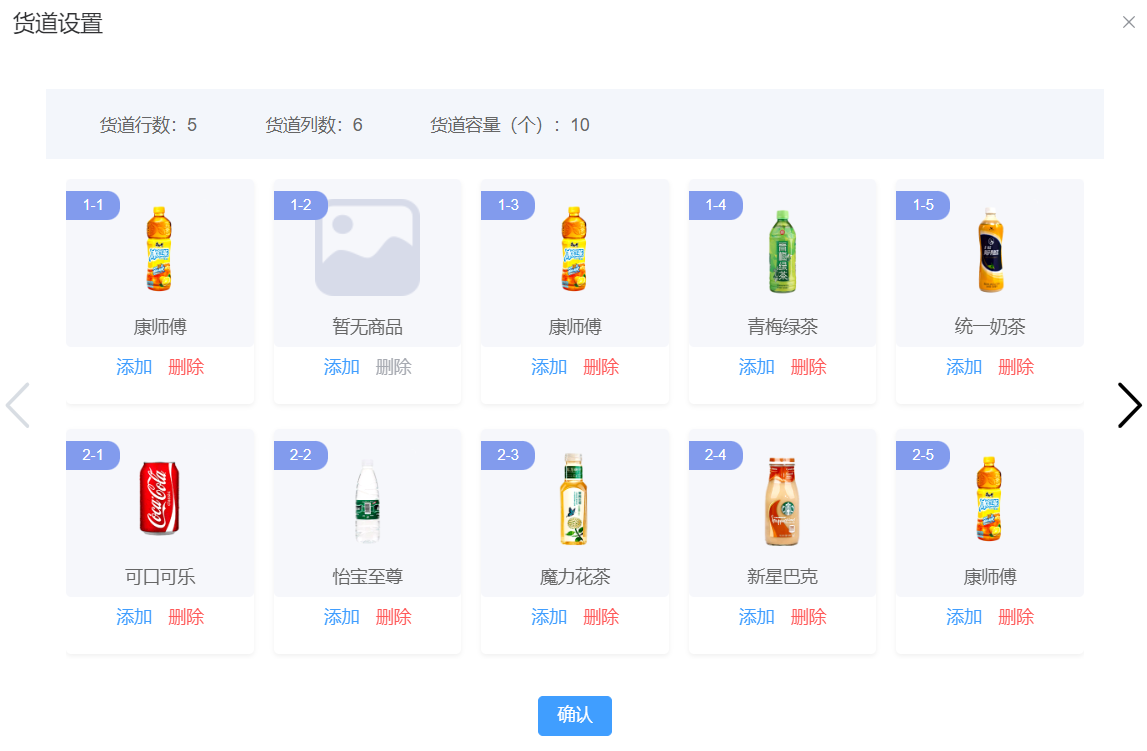

```text
GET  /vending-machine/channel/{innerCode}
POST /vending-machine/channel/config
      DTO: [{channelId, skuId, price, ...}]
```

保存接口应在 Service 层校验货道属于当前设备、商品处于可售状态，并使用事务保证一组货道配置要么全部成功，要么全部回滚。


## 17. 工单管理：状态机与数据模型

管理员创建工单，工作人员在运营管理 App 中接受、取消或完成任务。工单分为运营工单（补货）和运维工单（投放、维修、撤机）。

状态字典：`1=待处理`、`2=已接收/进行中`、`3=已取消`、`4=已完成`；创建类型 `0=自动、1=手动`。核心关系字段包括 `task_id`、`product_type_id`、`inner_code`、`user_id`、`assignor_id`、`region_id`。

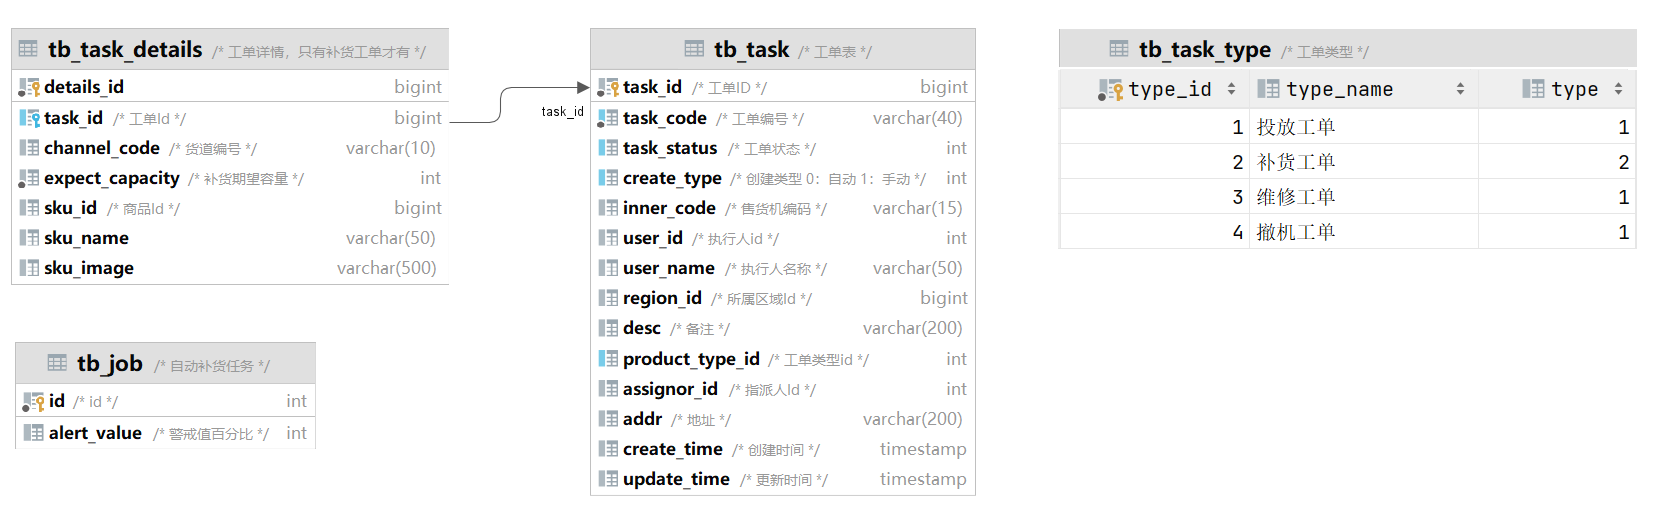

运营和运维工单可以共享后端接口，通过查询条件（课件中以 `isRepair` 为例）区分类型，再在 `TaskVo` 中嵌套返回工单类型、设备、员工等详情。


## 18. 工单列表与按区域获取员工

查询工单列表的分层职责：Controller 接收 `Task` 查询条件；Service 调用 Mapper；Mapper 返回 `TaskVo`，在 XML 中按 `isRepair` 拼接条件并嵌套工单类型信息。列表页可以用同一套分页接口展示两种工单。

创建工单前，还要根据售货机编号找到它所属区域，再筛选该区域的运营人员或运维人员。接口链路是：接收 `innerCode` → 查询售货机 → 取得 `region_id` → 按角色和区域查询员工 → 返回人员列表。这样可以避免把任务分配给不负责该区域的人。

```text
GET /task/operators?innerCode=VM001
GET /task/maintainers?innerCode=VM001
```

**面试提示**：把“设备属于哪个区域”和“员工负责哪个区域”作为服务端校验，而不是只依赖前端下拉框；前端输入永远不能替代权限与业务约束。


## 19. 新增工单：业务校验、事务与补货明细

运维工单和运营工单共享新增接口；补货工单额外保存多条商品明细。课件流程可以落成以下校验链：

```text
校验售货机存在
  → 校验设备状态与工单类型匹配
  → 检查是否已有未完成的同类型工单
  → 校验员工存在且区域匹配
  → TaskDto 转 Task 并保存
  → 若为补货工单，TaskDetailsDto 转明细并批量保存
```

Controller 接收 `TaskDto` 并设置指派人；Service 负责全部业务校验和事务；Mapper 批量插入工单明细。任何一步失败，都不应留下只有主表、没有明细的半成品工单。

```java
@Transactional(rollbackFor = Exception.class)
public Long createTask(TaskDto dto) {
    validateMachineAndEmployee(dto);
    Task task = toTask(dto);
    taskMapper.insert(task);
    if (dto.isReplenishment()) {
        detailMapper.batchInsert(toDetails(task.getId(), dto.getDetails()));
    }
    return task.getId();
}
```


## 20. 工单详情、取消与补货明细

管理员可查看运维/运营工单详情；未完成工单允许取消；运营端可查看补货明细。

| 用例 | Controller 输入 | Service 规则 | Mapper |
|---|---|---|---|
| 查看工单 | `Task` / `taskId` | 组装详情或查询明细 | 复用生成的查询方法 |
| 取消工单 | `Task` | 仅待处理/进行中可取消，设置状态和更新字段 | 复用更新工单 |
| 查看补货详情 | `taskId` | 封装条件并返回明细集合 | 复用明细查询 |

取消操作应返回明确的状态冲突提示，例如“已完成工单不能取消”，并记录操作者和时间。


## 21. Swagger 与 Knife4j：让接口可验证

Swagger 能根据接口注解生成在线 API 文档，并提供页面进行调用和测试。若团队更偏好前端化的交互界面，可使用 Knife4j 作为增强方案。

接口文档至少应说明请求方式、路径、参数、响应状态码、分页字段和错误示例。对本项目来说，文档既是前后端分离的协作契约，也是开发人员确认“列表、详情、保存、取消”接口边界的最快入口。


## 22. 运营管理 App：复用工单后端

运营管理 App 的场景是工作人员查看分配给自己的工单，并选择接受、拒绝/取消和完成。课件提供已完成的 APK 和 Java 后端源码，测试时安装模拟器、安装 APK、配置后端地址即可。

App 后端技术栈：Spring Boot + MyBatis-Plus + 阿里云短信。模块包括：

- 员工管理：短信发送、App 登录、查询员工信息。
- 工单管理：查询、接受、拒绝/取消、完成工单。
- 工单详情：按工单 ID 查询补货详情列表。

App 是新的客户端，不代表要复制一套业务规则；状态流转、区域校验和工单权限仍应由服务端统一控制。


## 23. 设备屏幕端与支付出货流程

消费者在设备屏幕端查看商品、选择支付方式、看到支付二维码，扫码支付后完成出货。屏幕端客户端由前端提供，打开 `index.html` 即可测试；Java 后端源码单独导入 IDEA，并通过 `innerCode` 指定要展示的设备。

支付链路不是“页面直接扣款”，而是：

```text
屏幕端 → 订单服务：创建订单并请求支付
订单服务 → 微信/支付宝：创建订单并返回支付二维码
用户扫码完成支付
支付平台 → 订单服务：异步通知支付结果
订单服务 → 屏幕端：返回/推送支付结果
设备控制器：校验已支付后出货
```

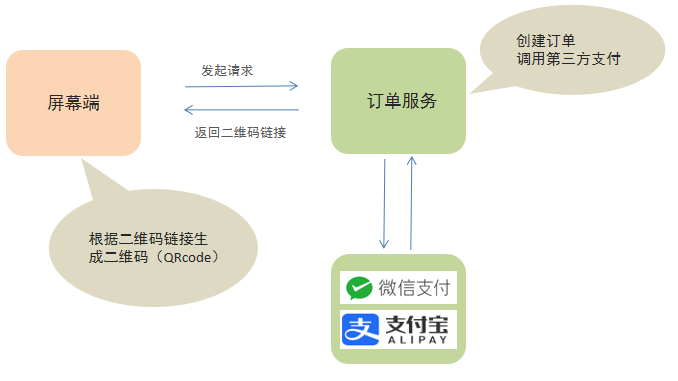

课件给出的优雅支付框架地址是 [elegent-pay](https://gitee.com/myelegent/elegent-pay)。生产实现还要考虑支付回调验签、幂等、订单超时和出货失败补偿。


## 24. 订单管理：后台运营闭环

后台管理人员需要查看订单信息，订单是“商品配置 → 设备屏幕 → 支付 → 出货”链路的最终运营凭证。订单列表至少要支持按订单号、设备编号、时间和状态筛选，并展示商品、金额、支付方式、支付时间和出货状态等字段。

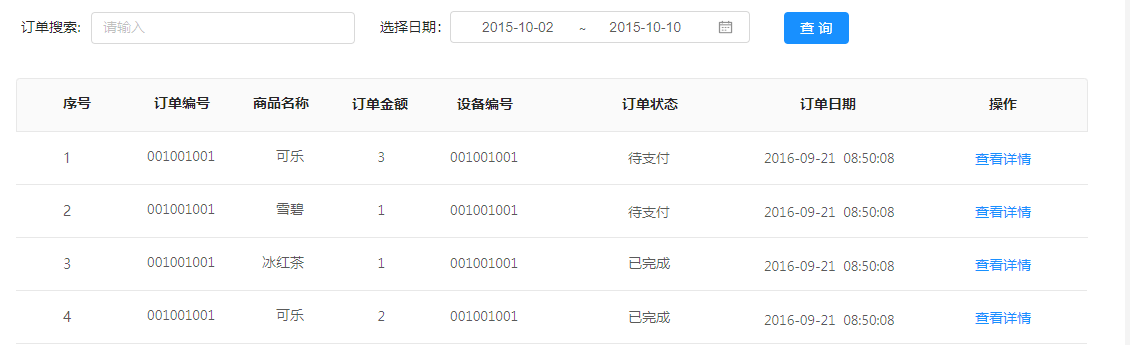

订单状态应与支付平台状态、设备出货状态分开建模，避免把“已支付”误当成“已出货”。对支付回调和设备回执要做幂等处理，重复通知不能重复扣库存或重复出货。


## 25. 贯穿全篇的实现套路

这个项目反复使用同一条可迁移的工程路径：

1. **需求与原型**：确认角色、流程、字段、状态和详情页。
2. **库表设计**：先确定主表、关联字段、字典和必要的冗余字段。
3. **生成基础代码**：用若依代码生成器生成菜单、Controller、Service、Mapper、XML、Vue 页面和 API。
4. **后端业务改造**：用 VO、关联查询、嵌套映射、事务和全局异常补齐业务语义。
5. **前端页面改造**：按原型调整布局、弹窗、路由、菜单和 API 参数。
6. **联调与验证**：先看接口文档和 Network，再用真实角色、状态和异常数据测试。

分层边界建议：Controller 只做参数接收与响应封装；Service 负责业务校验和事务；Mapper 负责持久化查询；前端 API 文件负责请求地址，Vue 组件负责交互和展示。这样生成代码可以保留，业务差异集中在可读的位置。


## 26. 高频检查清单与面试提示

- 为什么区域列表用 `LEFT JOIN`？因为要保留没有点位的区域。
- 为什么设备新增要事务？设备、货道和冗余字段必须整体成功或整体回滚。
- `association` 和 `collection` 做什么？前者映射关联对象，后者映射关联集合。
- 物理外键和逻辑外键如何选？强一致关系优先物理约束；需要跨库或自定义业务提示时由 Service 校验，但数据库仍应有兜底策略。
- 冗余字段的风险是什么？主表修改后未同步会产生脏展示；必须定义同步入口和修复脚本。
- 为什么工单接口可以共用？公共字段和生命周期相同，用查询条件、类型字段和明细表表达差异。
- 为什么支付回调要幂等？同一通知可能重试，重复处理会导致重复出货或重复扣库存。
- AI 怎样参与开发？先用明确的角色、上下文、输入和输出格式让 AI 生成表结构、接口草稿、流程图或测试清单，再由工程师核对权限、事务、数据一致性和安全边界。

这些问题覆盖了课件里最容易从“会点页面”追问到“理解系统”的部分。
